<a href="https://colab.research.google.com/github/ZidAvwa/PCVK_Ganjil_2026/blob/main/Week9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**D1.1 - mount Google Drive**

---

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**D1.2 - Import the libraries**

---

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, color, io, morphology
from skimage import img_as_float
from skimage.morphology import skeletonize

In [3]:
IMAGES = '/content/drive/MyDrive/PCVK Semester 5/Images'
PLATE_FILE = '/content/drive/MyDrive/PCVK Semester 5/platenumber.jpg'

def read_image(path, flag=cv.IMREAD_COLOR):
    img = cv.imread(path, flag)
    if img is None:
        raise FileNotFoundError('Image not found: ' + path)
    return img

def show_row(images, titles, figsize=(12, 4)):
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(images, titles)):
        if im.dtype == bool:
            im = im.astype(np.uint8) * 255
        plt.subplot(1, len(images), i + 1)
        plt.imshow(im, 'gray', vmin=0, vmax=255, interpolation='nearest')
        plt.title(t)
        plt.xticks([]), plt.yticks([])
    plt.show()

def binarize(gray, t=127):
    return cv.threshold(gray, t, 255, cv.THRESH_BINARY)[1]

plate = read_image(PLATE_FILE, cv.IMREAD_GRAYSCALE)
print('Plate image shape:', plate.shape)

Plate image shape: (780, 1040)


**D1.3 - Dilation without library (Cross 3 x 3 SED)**

---

Dilation and erosion are written with NumPy only. For every non-zero cell of the structuring element the image is shifted by that offset, then the shifted copies are combined with `np.maximum` (dilation) or `np.minimum` (erosion). This gives the same result as sliding the SE over the image and taking the max / min under it.

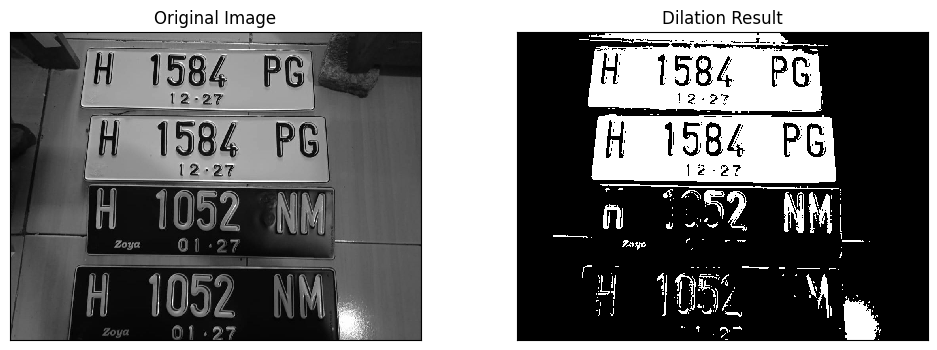

In [4]:
def dilasi_citra(F, SE):
    h, w = F.shape
    ph, pw = SE.shape[0] // 2, SE.shape[1] // 2
    padded = np.pad(F, ((ph, ph), (pw, pw)), constant_values=0)
    out = np.zeros_like(F)
    for dy, dx in zip(*np.nonzero(SE)):
        out = np.maximum(out, padded[dy:dy + h, dx:dx + w])
    return out

def cross(k):
    return cv.getStructuringElement(cv.MORPH_CROSS, (k, k))

thresh = binarize(plate, 125)
imgD = dilasi_citra(thresh, cross(3))

show_row([plate, imgD], ['Original Image', 'Dilation Result'])

**D1.4 - Dilation with OpenCV library (Cross 3 x 3 SED)**

---

[[0 1 0]
 [1 1 1]
 [0 1 0]]


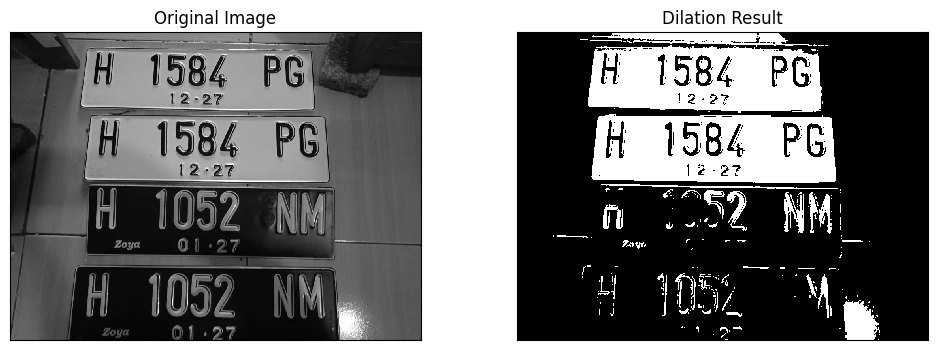

In [5]:
thresh = binarize(plate, 127)
kernel = cross(3)
dilasi = cv.dilate(thresh, kernel, iterations=1)
print(kernel)

show_row([plate, dilasi], ['Original Image', 'Dilation Result'])

**Check** - the manual dilation must be identical to `cv.dilate` (the library is used only for this check).

In [6]:
manual = dilasi_citra(thresh, cross(3))
print('Max difference vs cv.dilate: %d' % np.abs(manual.astype(int) - dilasi.astype(int)).max())
assert np.array_equal(manual, dilasi)

Max difference vs cv.dilate: 0


**Observation (D1.3 - D1.4)** - the white regions grow: the plates and the bright glare become larger, the thin black letters on the white plates become thinner (and the small `12·27` text starts to break up), while the white letters on the dark plates become thicker. The manual dilation is identical to `cv.dilate` (difference 0).

**D1.5 - Erosion without library (Square 5 x 5 SE)**

---

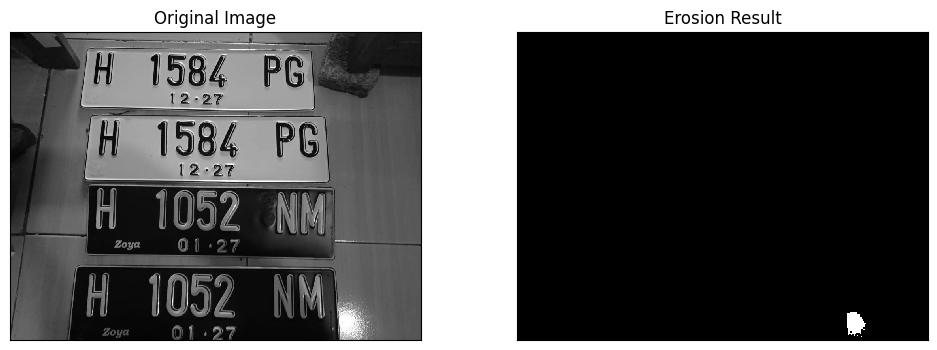

In [7]:
def erosi_citra(F, SE):
    h, w = F.shape
    ph, pw = SE.shape[0] // 2, SE.shape[1] // 2
    padded = np.pad(F, ((ph, ph), (pw, pw)), constant_values=255)
    out = np.full_like(F, 255)
    for dy, dx in zip(*np.nonzero(SE)):
        out = np.minimum(out, padded[dy:dy + h, dx:dx + w])
    return out

def square(k):
    return np.ones((k, k), dtype=np.uint8)

thresh1 = binarize(plate, 175)
imgE = erosi_citra(thresh1, square(5))

show_row([plate, imgE], ['Original Image', 'Erosion Result'])

**D1.6 - Erosion with OpenCV library (Square 5 x 5 SE)**

---

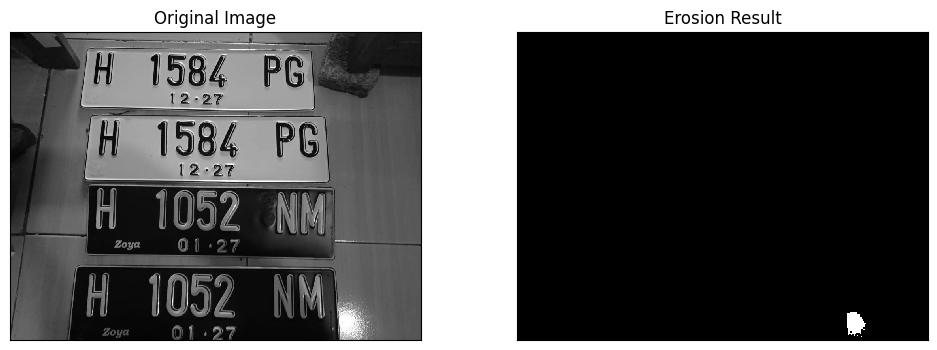

In [8]:
thresh1 = binarize(plate, 175)
erosion = cv.erode(thresh1, square(5), iterations=1)

show_row([plate, erosion], ['Original Image', 'Erosion Result'])

**Check** - the manual erosion must be identical to `cv.erode`. The border is padded with 255 (the neutral value of a minimum), the same as OpenCV does, so the image edge is not eroded by mistake.

In [9]:
manual = erosi_citra(thresh1, square(5))
print('Max difference vs cv.erode: %d' % np.abs(manual.astype(int) - erosion.astype(int)).max())
assert np.array_equal(manual, erosion)

Max difference vs cv.erode: 0


**Observation (D1.5 - D1.6)** - with a threshold of 175 only the brightest pixels are white, and the 5 x 5 erosion deletes every white structure narrower than 5 px, which includes all the letter strokes. Only the large glare area at the bottom right survives. Erosion shrinks objects and removes thin details, the opposite of dilation. The manual result is identical to `cv.erode` (difference 0).

**D1.7 - Opening (Square 3 x 3 SE)**

---

Opening = erosion followed by dilation with the same SE.

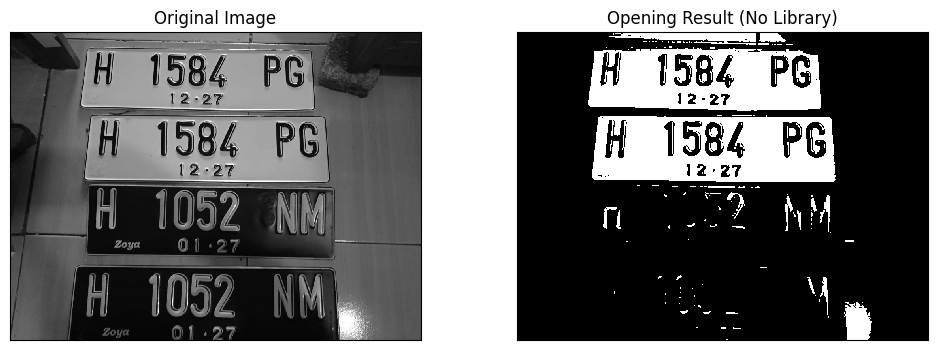

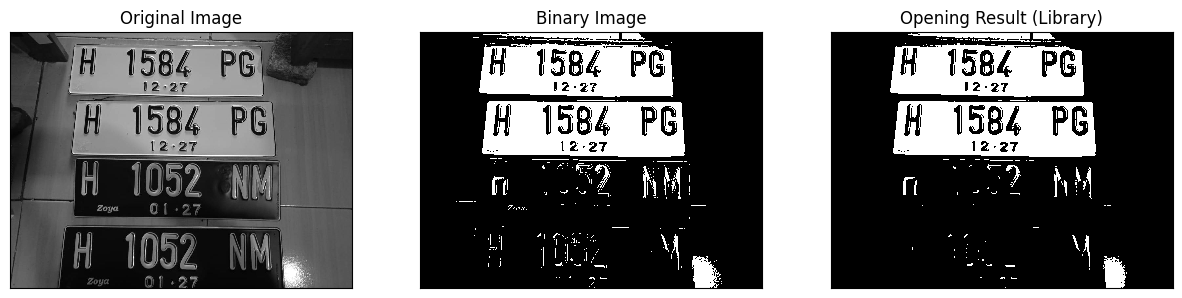

Max difference between manual and library opening: 0


In [10]:
thresh = binarize(plate, 127)

imgO = dilasi_citra(erosi_citra(thresh, square(3)), square(3))
show_row([plate, imgO], ['Original Image', 'Opening Result (No Library)'])

openn = cv.morphologyEx(thresh, cv.MORPH_OPEN, square(3))
show_row([plate, thresh, openn], ['Original Image', 'Binary Image', 'Opening Result (Library)'], (15, 4))

print('Max difference between manual and library opening: %d' % np.abs(imgO.astype(int) - openn.astype(int)).max())

**Observation (D1.7)** - opening (erosion, then dilation) removes isolated white specks and very thin white lines, but the large objects keep their size and shape. With a 3 x 3 SE the change from the binary image is small. Manual and library results are identical (difference 0).

**D1.8 - Closing (Square 3 x 3 SE)**

---

Closing = dilation followed by erosion with the same SE.

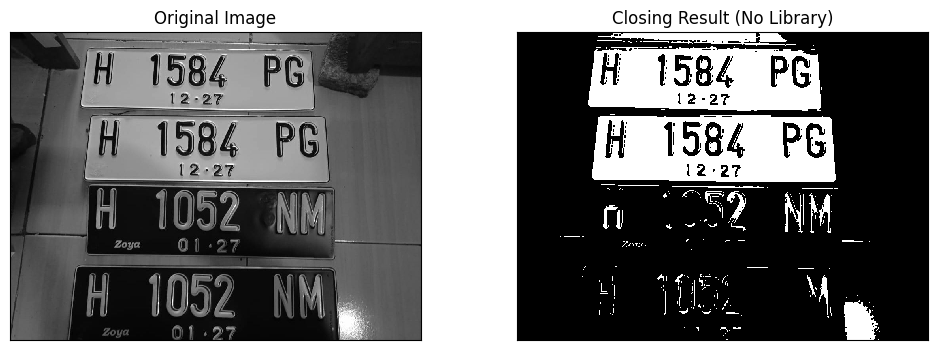

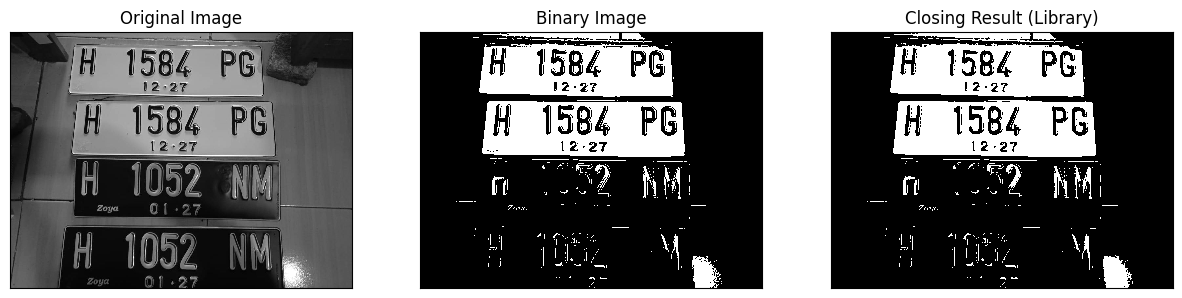

Max difference between manual and library closing: 0


In [11]:
thresh = binarize(plate, 127)

imgC = erosi_citra(dilasi_citra(thresh, square(3)), square(3))
show_row([plate, imgC], ['Original Image', 'Closing Result (No Library)'])

closs = cv.morphologyEx(thresh, cv.MORPH_CLOSE, square(3))
show_row([plate, thresh, closs], ['Original Image', 'Binary Image', 'Closing Result (Library)'], (15, 4))

print('Max difference between manual and library closing: %d' % np.abs(imgC.astype(int) - closs.astype(int)).max())

**Observation (D1.8)** - closing (dilation, then erosion) is the dual of opening: it fills small black holes and gaps inside the white regions while the outer size of the objects is kept. With a 3 x 3 SE the change is small. Manual and library results are identical (difference 0).

**D1.9 - Dilation (Cross 3 x 3 and 5 x 5 SED)**

---

SED = Cross 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]


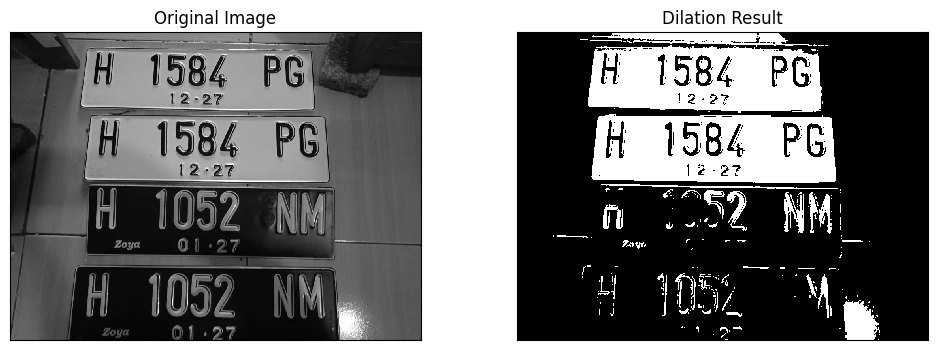

SED = Cross 5
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]


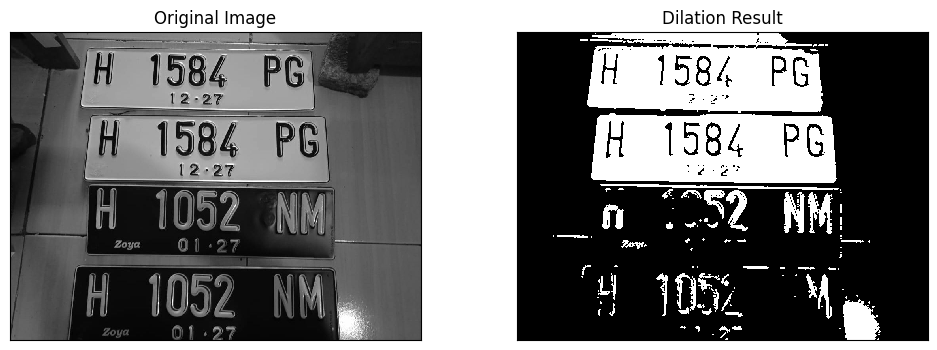

In [12]:
thresh = binarize(plate, 127)
for k in (3, 5):
    print('SED = Cross %d' % k)
    print(cross(k))
    show_row([plate, dilasi_citra(thresh, cross(k))], ['Original Image', 'Dilation Result'])

**Observation (D1.9)** - a larger SE grows the objects more: with Cross 5 the black letters on the white plates are thinner and the `12·27` text almost disappears, and the white letters on the dark plates are thicker than with Cross 3. A cross only reaches along the horizontal and vertical axes, so it grows objects less on the diagonals than a full square.

**D1.10 - Dilation (Circular 3 x 3 and 5 x 5 SED)**

---

SED = Circle 3
[[0 1 0]
 [1 1 1]
 [0 1 0]]


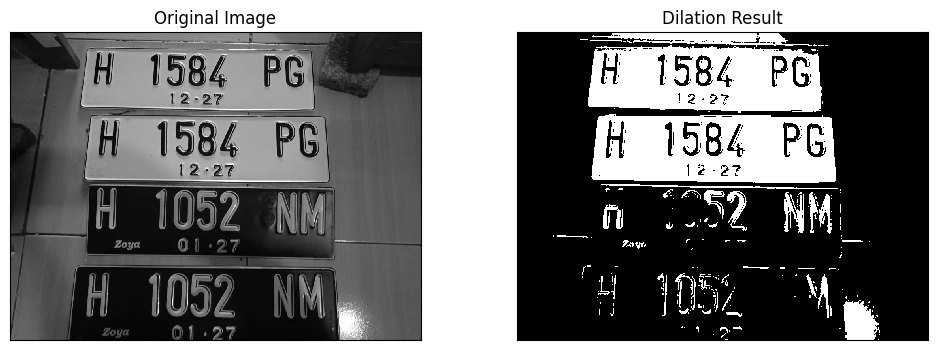

SED = Circle 5
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


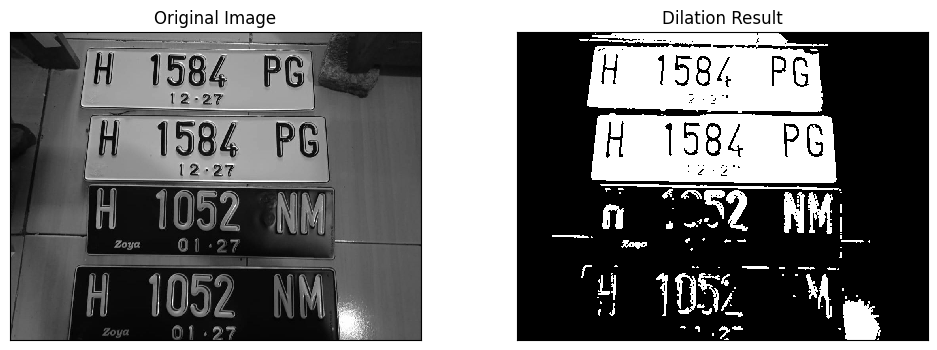

In [13]:
def circle(k):
    return cv.getStructuringElement(cv.MORPH_ELLIPSE, (k, k))

thresh = binarize(plate, 127)
for k in (3, 5):
    print('SED = Circle %d' % k)
    print(circle(k))
    show_row([plate, dilasi_citra(thresh, circle(k))], ['Original Image', 'Dilation Result'])

**Observation (D1.10)** - the printed kernels show that the circular 3 x 3 SE of OpenCV is the same as the cross 3 x 3, so both give the same result. The circular 5 x 5 SE is a fuller disc (rows of 1 1 1 1 1), so it grows objects more evenly in all directions, and the result is thicker than Cross 5.

**D1.11 - Erosion (Rectangle 3 x 5 and 5 x 7 SE)**

---

SE = Rectangle 3x5


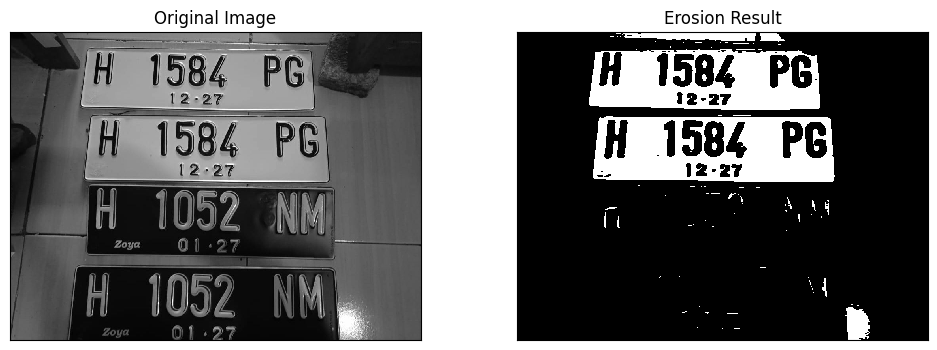

SE = Rectangle 5x7


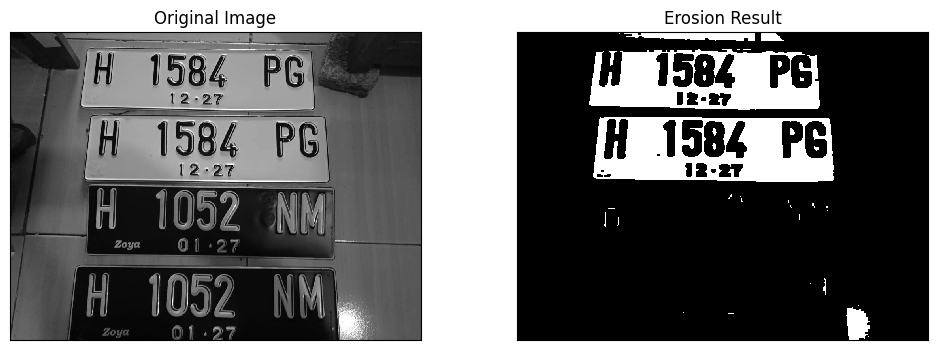

In [14]:
def rect(w, h):
    return cv.getStructuringElement(cv.MORPH_RECT, (w, h))

thresh = binarize(plate, 127)
for w, h in ((5, 3), (7, 5)):
    print('SE = Rectangle %dx%d' % (h, w))
    show_row([plate, erosi_citra(thresh, rect(w, h))], ['Original Image', 'Erosion Result'])

**Observation (D1.11)** - the white plates shrink at their borders, the black letters on the white plates become fatter, and the white letters on the dark plates almost vanish. The 5 x 7 rectangle removes much more than the 3 x 5 rectangle: the lower plates are nearly empty.

**D1.12 - Erosion (Vertical Line 3 and 5 SE, image j.png)**

---

SE = Vertical Line 3


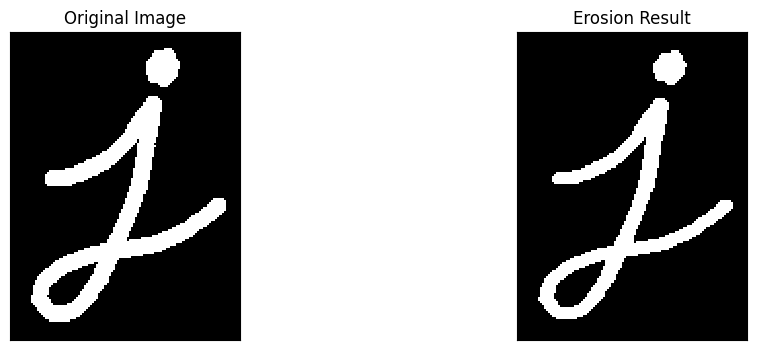

SE = Vertical Line 5


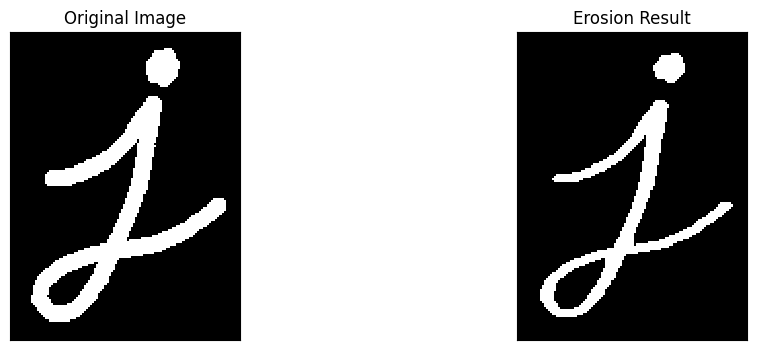

In [15]:
def vline(k):
    return cv.getStructuringElement(cv.MORPH_RECT, (1, k))

filename = IMAGES + '/j.png'
j_img = cv.imread(filename, cv.IMREAD_GRAYSCALE)
if j_img is None:
    j_img = np.zeros((200, 200), dtype=np.uint8)
    cv.putText(j_img, 'J', (50, 160), cv.FONT_HERSHEY_SIMPLEX, 5, 255, 12)
    print('j.png not found, a synthetic letter J is used instead')

j_bin = binarize(j_img, 127)
for k in (3, 5):
    print('SE = Vertical Line %d' % k)
    show_row([j_img, erosi_citra(j_bin, vline(k))], ['Original Image', 'Erosion Result'])

**Observation (D1.12)** - a vertical line SE only checks the pixels above and below, so only the thickness measured along the vertical direction shrinks. The near-horizontal strokes of the `j` (the left arm and the bottom of the loop) become thinner, while the vertical stem keeps its width. The effect is small for length 3 and clear for length 5.

**D1.13 - Top Hat**

---

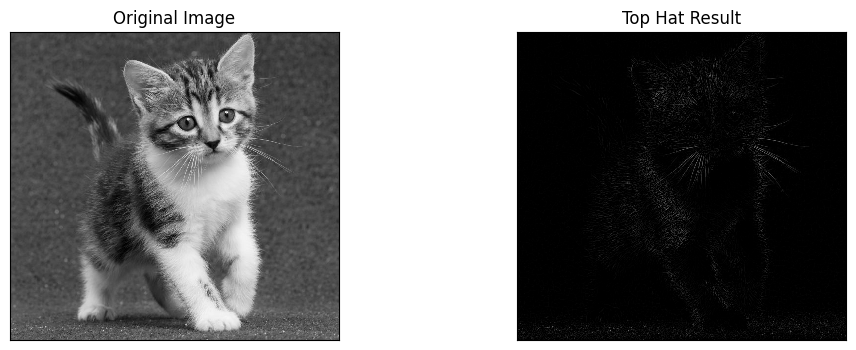

In [16]:
filename = IMAGES + '/kitten01.jpg'
kitten = read_image(filename, cv.IMREAD_GRAYSCALE)

kernel = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
tophat_img = cv.morphologyEx(kitten, cv.MORPH_TOPHAT, kernel)

show_row([kitten, tophat_img], ['Original Image', 'Top Hat Result'])

**D1.14 - Black Hat**

---

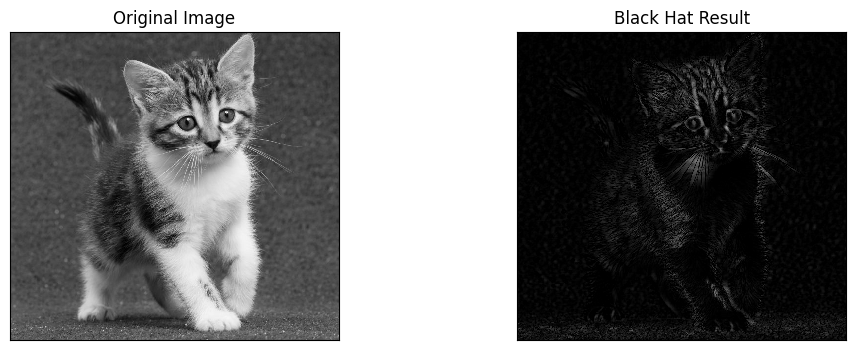

In [17]:
kernel = cv.getStructuringElement(cv.MORPH_RECT, (13, 5))
blackhat = cv.morphologyEx(kitten, cv.MORPH_BLACKHAT, kernel)

show_row([kitten, blackhat], ['Original Image', 'Black Hat Result'])

**Observation (D1.13 - D1.14)** - both results are mostly black, because the large structures of the image are removed. Top hat (image - opening) keeps the *bright* details smaller than the SE, such as the whiskers and the fur highlights. Black hat (closing - image) keeps the *dark* details smaller than the SE, such as the eyes, the nose and the dark stripes of the fur. The SE size decides which detail size is kept.

**D1.15 - Skeleton**

---

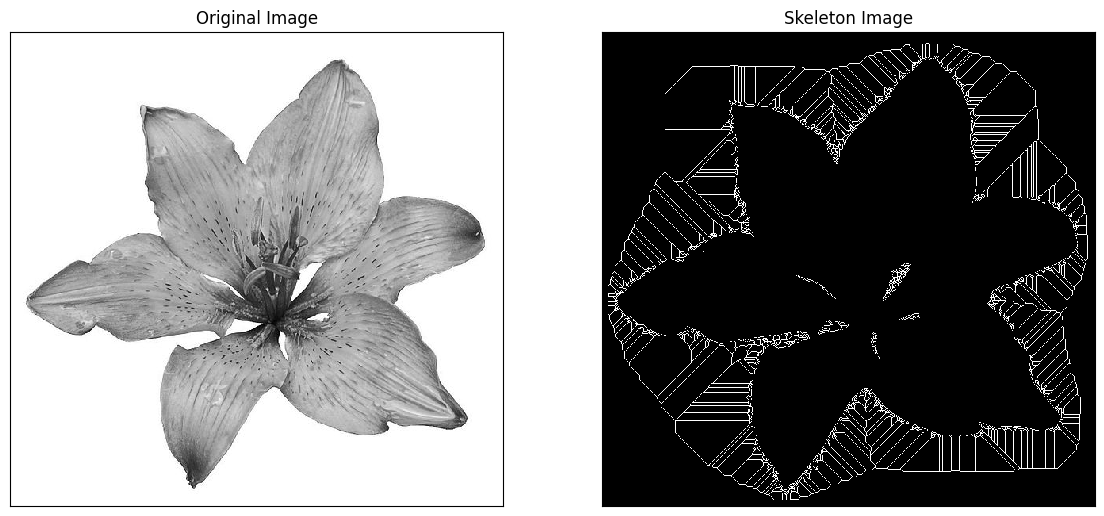

In [18]:
filename = IMAGES + '/lily.jpg'
lily = read_image(filename, cv.IMREAD_GRAYSCALE)

binary = lily > filters.threshold_triangle(lily)
skeleton = skeletonize(binary)

show_row([lily, skeleton], ['Original Image', 'Skeleton Image'], (14, 7))

**D1.16 - Skeleton Inverse**

---

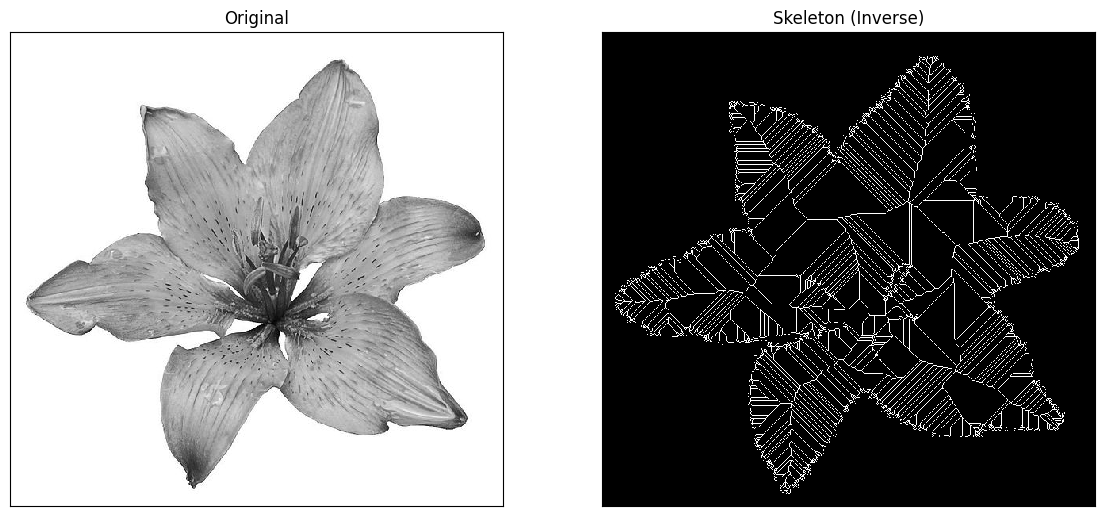

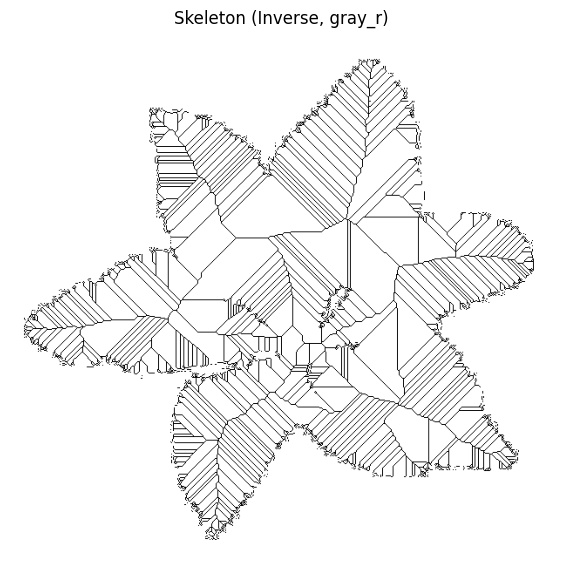

In [19]:
binary_inv = lily < filters.threshold_triangle(lily)
skeleton_inv = skeletonize(binary_inv)

show_row([lily, skeleton_inv], ['Original', 'Skeleton (Inverse)'], (14, 7))

plt.figure(figsize=(7, 7))
plt.imshow(skeleton_inv, cmap='gray_r')
plt.title('Skeleton (Inverse, gray_r)')
plt.axis('off')
plt.show()

**Observation (D1.15 - D1.16)** - the object must be the `True` region. In D1.15 the test is `img > threshold`, so the bright background is the object and the skeleton is drawn in the white area around the flower, while the flower itself is empty. In D1.16 the test is `img < threshold`, so the petals are the object and the skeleton lies inside them: a line along each petal with side branches, joined near the centre of the flower. A skeleton is thin (1 px), connected and lies in the middle of the object.

**D1.17 - Thickening**

---

`morphology.thin` removes pixels from the object, so the thickening is obtained by thinning the background (the complement) and inverting the result.

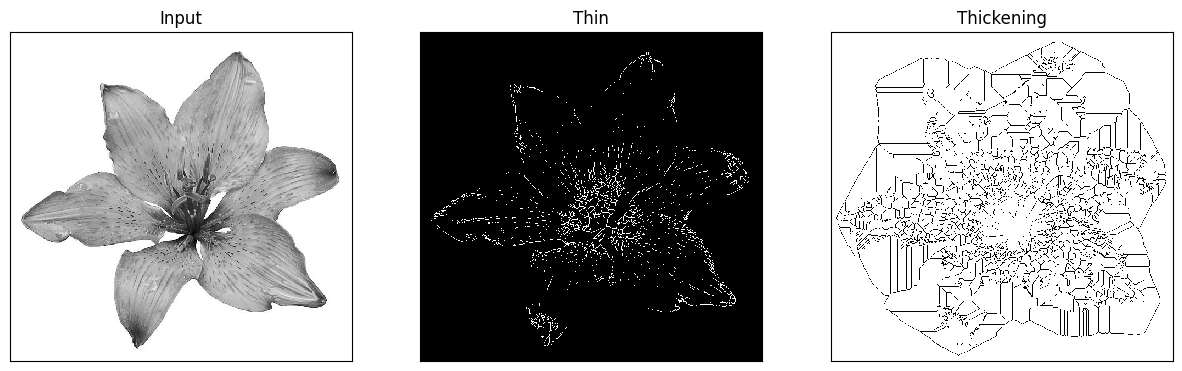

In [20]:
image = img_as_float(lily)
image_binary = image < 0.5
out_thin = morphology.thin(image_binary)
out_thick = ~morphology.thin(~image_binary)

show_row([image * 255, out_thin, out_thick], ['Input', 'Thin', 'Thickening'], (15, 5))

**Observation (D1.17)** - `Thin` removes pixels from the dark object (veins and spots), so only thin lines remain. `Thickening` is the dual: the background is thinned and the result is inverted, so the object grows until only thin lines of background remain between the grown regions. This is why the third image is mostly white with thin black lines.

**E - Practical Task: Morphology on the ID card (KTP) so that it can be read by OCR**

---

This task uses the ID card (KTP) image from Module 7 (`KTP_FILE`). The goal is that the card is read as well as possible by OCR (Tesseract) after morphology is applied. Six input images are compared:

| No. | Input image | What it is |
|---|---|---|
| 1 | Original color | baseline, no segmentation |
| 2 | Otsu | baseline from Week 7 |
| 3 | Adaptive | baseline from Week 7 (Gaussian, 31 x 31, C = 10) |
| 4 | Adaptive + Opening | the adaptive result still has black specks and lines from the guilloche pattern. The text is made white, a 2 x 2 **opening** removes the thin specks, and the result is inverted back |
| 5 | Black Hat + Otsu | the **black hat** (Closing - image, 15 x 15 rectangle) keeps only the dark details that are thinner than the SE, which are the text strokes, and removes the smooth blue background. Otsu then separates the text |
| 6 | Black Hat + Otsu + Closing | same as 5, followed by a 2 x 2 **closing** on the white text to reconnect strokes that were broken by the threshold |

Black hat is the operation expected to suit this card: the text is dark and thin, the background is bright and smooth, and the faint pattern lines have a much lower contrast than the text.

**Step 0 - Install Tesseract**

In [21]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


**Step 1 - Prepare the six input images.**

Otsu threshold: 151


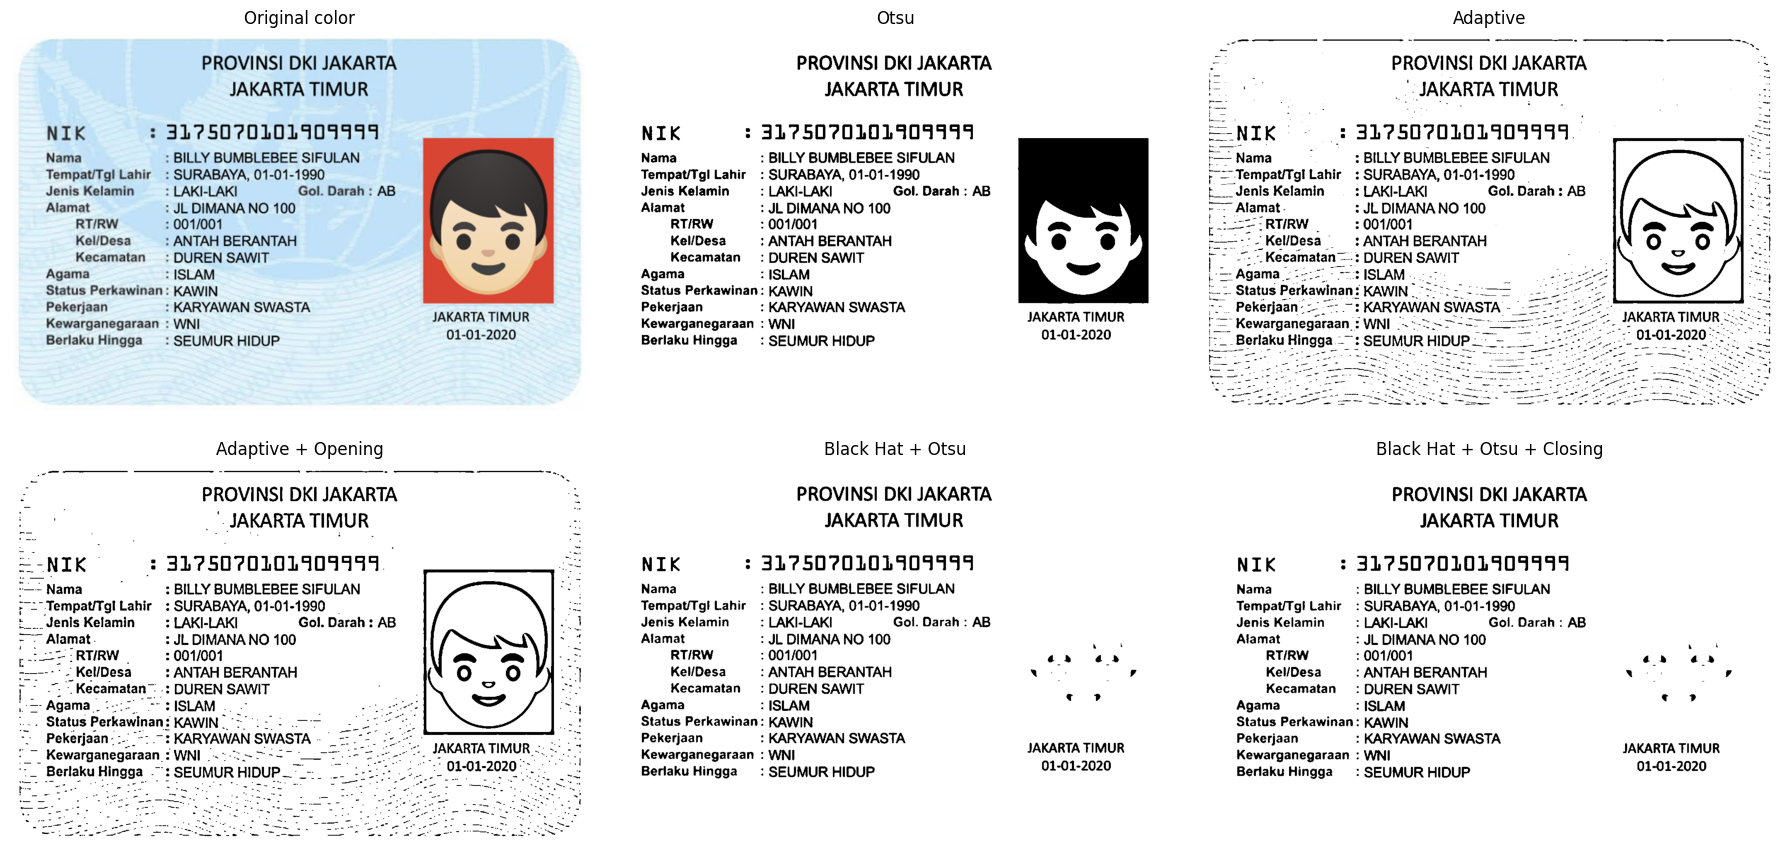

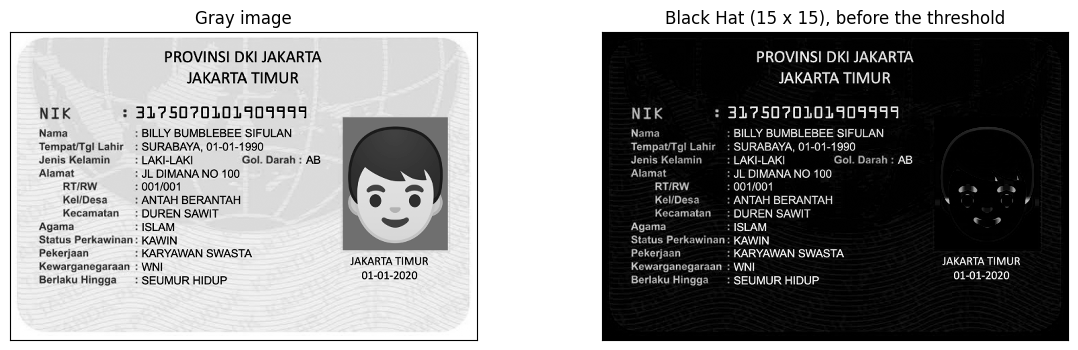

In [22]:
import re
import difflib
import pandas as pd
import pytesseract
from pytesseract import Output

KTP_FILE = '/content/drive/MyDrive/PCVK Semester 5/Images/ktp_fulan.jpg'
LANG = 'ind'
CONFIG = '--psm 6'
CONF_MIN = 60
WIDTH = 1400
BH_SIZE = 15

def rect(w, h):
    return cv.getStructuringElement(cv.MORPH_RECT, (w, h))

def square(k):
    return np.ones((k, k), dtype=np.uint8)

ktp_bgr = read_image(KTP_FILE)
scale = WIDTH / ktp_bgr.shape[1]
ktp_bgr = cv.resize(ktp_bgr, None, fx=scale, fy=scale, interpolation=cv.INTER_CUBIC)
ktp_gray = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2GRAY)

# Baselines (Week 7)
otsu_value, ktp_otsu_img = cv.threshold(ktp_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
ktp_adaptive_img = cv.adaptiveThreshold(ktp_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 31, 10)

# 4. Adaptive + Opening (text = white while the morphology runs, then inverted back)
adaptive_text = cv.bitwise_not(ktp_adaptive_img)
ktp_adaptive_open = cv.bitwise_not(cv.morphologyEx(adaptive_text, cv.MORPH_OPEN, rect(2, 2)))

# 5. Black Hat + Otsu
blackhat_ktp = cv.morphologyEx(ktp_gray, cv.MORPH_BLACKHAT, rect(BH_SIZE, BH_SIZE))
_, blackhat_text = cv.threshold(blackhat_ktp, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
ktp_blackhat = cv.bitwise_not(blackhat_text)

# 6. Black Hat + Otsu + Closing
ktp_blackhat_close = cv.bitwise_not(cv.morphologyEx(blackhat_text, cv.MORPH_CLOSE, rect(2, 2)))

names = ['Original color', 'Otsu', 'Adaptive', 'Adaptive + Opening', 'Black Hat + Otsu', 'Black Hat + Otsu + Closing']
inputs = [ktp_bgr, ktp_otsu_img, ktp_adaptive_img, ktp_adaptive_open, ktp_blackhat, ktp_blackhat_close]
print('Otsu threshold:', int(otsu_value))

plt.figure(figsize=(18, 9))
for i, (im, t) in enumerate(zip(inputs, names)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB) if im.ndim == 3 else im, 'gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
plt.tight_layout()
plt.show()

show_row([ktp_gray, blackhat_ktp], ['Gray image', 'Black Hat (15 x 15), before the threshold'], (14, 4))

**Step 2 - Read the text** with Tesseract (Indonesian language).

In [23]:
def run_ocr(img):
    rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img
    text = pytesseract.image_to_string(rgb, lang=LANG, config=CONFIG)
    info = pytesseract.image_to_data(rgb, lang=LANG, config=CONFIG, output_type=Output.DICT)
    return text, info

results = [run_ocr(im) for im in inputs]
for name, (text, info) in zip(names, results):
    print('=== %s ===' % name)
    print(text.strip())
    print()

=== Original color ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 3275070101909447
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH t 4

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

=== Otsu ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 3275070101409147
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Atamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga: SEUMUR HIDUP 01-01-2020

=== Adaptive ===
- PROVINSI DKI JAKARTA 1
Po JAKARTA TIMUR 5
—. Pos “. 25 | | 2 ae
—NIK - 3: 31?5070101109199. ss
#— Nama : : BILLY BU

**Step 3 - Recognised text areas** (`pytesseract.image_to_data()`, only words with a confidence above `CONF_MIN`).

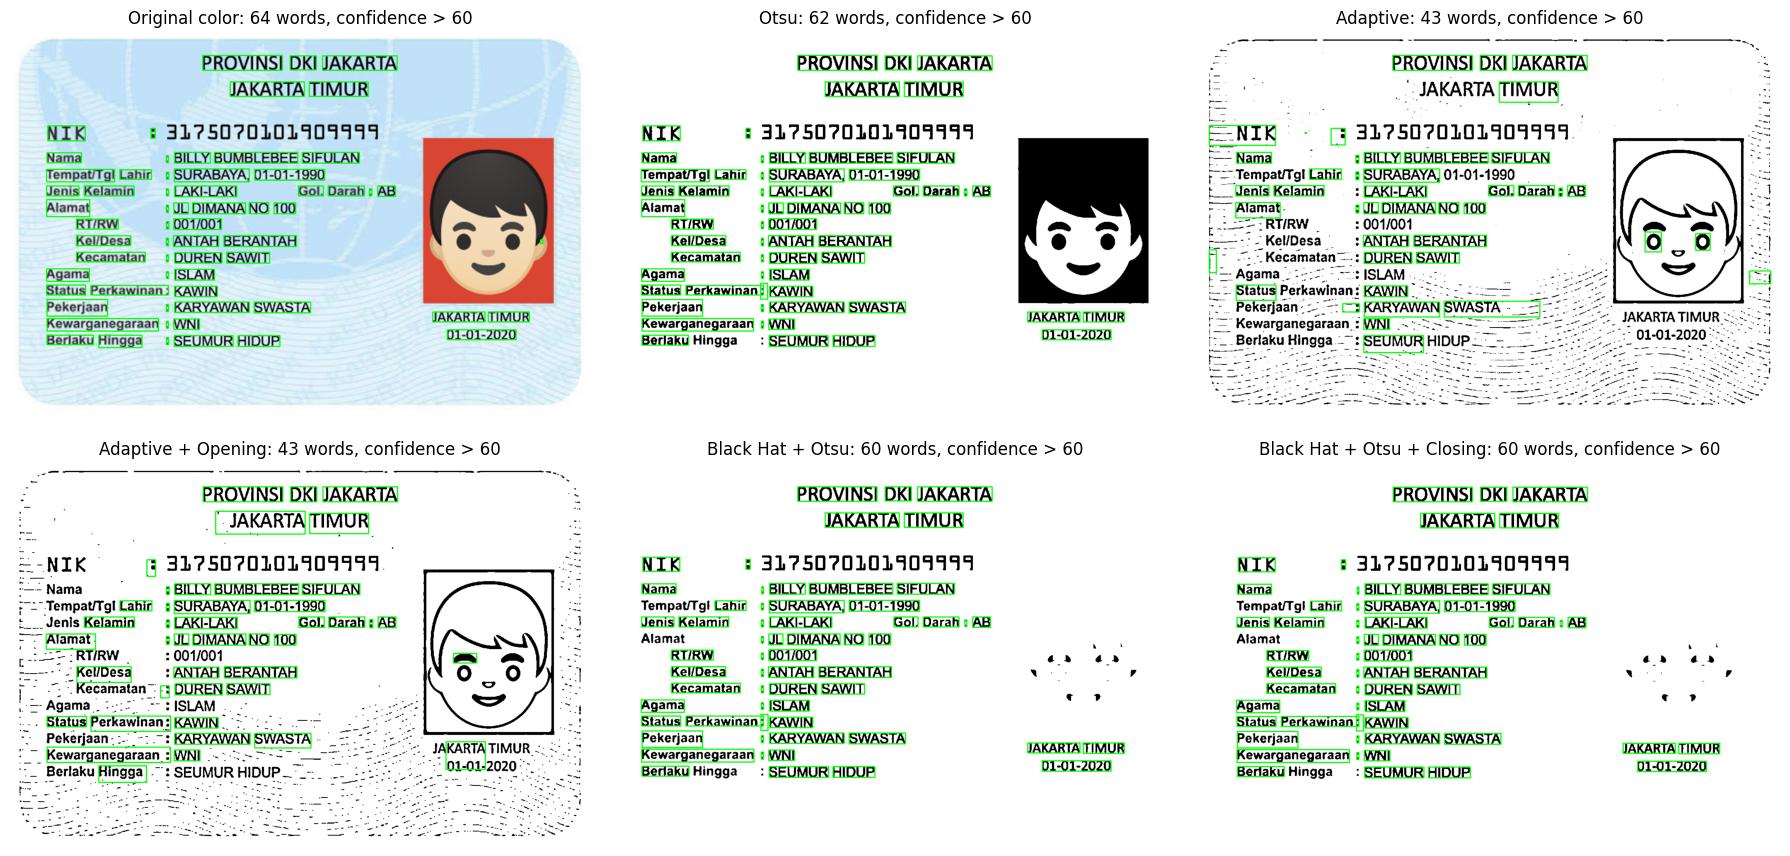

In [24]:
def draw_boxes(img, info, conf_min):
    canvas = cv.cvtColor(img, cv.COLOR_GRAY2BGR) if img.ndim == 2 else img.copy()
    count = 0
    for i in range(len(info['text'])):
        if info['text'][i].strip() and float(info['conf'][i]) > conf_min:
            x, y, w, h = info['left'][i], info['top'][i], info['width'][i], info['height'][i]
            cv.rectangle(canvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
            count += 1
    return canvas, count

plt.figure(figsize=(18, 9))
for i, (name, im, (text, info)) in enumerate(zip(names, inputs, results)):
    boxed, count = draw_boxes(im, info, CONF_MIN)
    plt.subplot(2, 3, i + 1)
    plt.imshow(cv.cvtColor(boxed, cv.COLOR_BGR2RGB))
    plt.title('%s: %d words, confidence > %d' % (name, count, CONF_MIN))
    plt.axis('off')
plt.tight_layout()
plt.show()

**Step 4 - Compare with the real text.** Two checks are used:

- **Labels**: the 10 field names of Week 7 (`PROVINSI`, `NIK`, `Nama`, ...).
- **Values**: the 14 values printed on the card (NIK, name, birth place and date, ..., `SEUMUR HIDUP`). The NIK must be read digit by digit, so a single wrong digit makes that item wrong.

An item counts as read exactly when it is found in the OCR text after lower-casing and removing punctuation. Spaces are ignored for multi-word items, because Tesseract sometimes merges words, and one-word items must appear as a whole word.

In [25]:
labels = ['PROVINSI', 'NIK', 'Nama', 'Alamat', 'Agama', 'Pekerjaan',
          'Kewarganegaraan', 'Berlaku Hingga', 'Jenis Kelamin', 'Status Perkawinan']

values = {'NIK': '3175070101909999',
          'Nama': 'BILLY BUMBLEBEE SIFULAN',
          'Tempat/Tgl Lahir': 'SURABAYA, 01-01-1990',
          'Jenis Kelamin': 'LAKI-LAKI',
          'Gol. Darah': 'AB',
          'Alamat': 'JL DIMANA NO 100',
          'RT/RW': '001/001',
          'Kel/Desa': 'ANTAH BERANTAH',
          'Kecamatan': 'DUREN SAWIT',
          'Agama': 'ISLAM',
          'Status Perkawinan': 'KAWIN',
          'Pekerjaan': 'KARYAWAN SWASTA',
          'Kewarganegaraan': 'WNI',
          'Berlaku Hingga': 'SEUMUR HIDUP'}

def clean(s):
    return re.sub(r'[^0-9a-z ]', '', s.lower())

def is_match(ref, text):
    r = clean(ref)
    tokens = [clean(w) for w in text.split() if clean(w)]
    if ' ' in r.strip():
        return r.replace(' ', '') in ''.join(tokens)
    return r in tokens

def nik_accuracy(text, true_nik=values['NIK']):
    got = ''
    for line in text.splitlines():
        if 'nik' in line.lower():
            got = re.sub(r'\D', '', line.lower().split('nik', 1)[1])
            break
    return difflib.SequenceMatcher(None, got, true_nik).ratio() * 100

def mean_conf(info):
    v = [float(c) for c, t in zip(info['conf'], info['text']) if t.strip() and float(c) >= 0]
    return sum(v) / len(v) if v else 0.0

rows = []
for name, (text, info) in zip(names, results):
    lab = sum(is_match(r, text) for r in labels)
    val = sum(is_match(v, text) for v in values.values())
    rows.append({'OCR input image': name,
                 'Labels (of 10)': lab,
                 'Values (of 14)': val,
                 'Match (%)': round((lab + val) / (len(labels) + len(values)) * 100, 1),
                 'NIK digits correct (%)': round(nik_accuracy(text), 1),
                 'Average confidence': round(mean_conf(info), 1)})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

           OCR input image  Labels (of 10)  Values (of 14)  Match (%)  NIK digits correct (%)  Average confidence
            Original color              10              13       95.8                    75.0                88.6
                      Otsu               9              13       91.7                    68.8                89.8
                  Adaptive              10              13       95.8                    81.2                40.4
        Adaptive + Opening              10              13       95.8                    81.2                44.0
          Black Hat + Otsu              10              13       95.8                    58.1                83.5
Black Hat + Otsu + Closing              10              13       95.8                    58.1                82.3


**Where are the mistakes?** For every input image, the items that were *not* read exactly.

In [26]:
for name, (text, info) in zip(names, results):
    missed = [r for r in labels if not is_match(r, text)] + [k + ' = ' + v for k, v in values.items() if not is_match(v, text)]
    print('%-28s %s' % (name, missed if missed else 'nothing missed'))

Original color               ['NIK = 3175070101909999']
Otsu                         ['Alamat', 'NIK = 3175070101909999']
Adaptive                     ['NIK = 3175070101909999']
Adaptive + Opening           ['NIK = 3175070101909999']
Black Hat + Otsu             ['NIK = 3175070101909999']
Black Hat + Otsu + Closing   ['NIK = 3175070101909999']


**Step 5 - Conclusion, written from the table above** (the sentences are generated from your own results, so they always agree with the numbers).

In [27]:
best = summary.sort_values(['Match (%)', 'NIK digits correct (%)'], ascending=False).iloc[0]
color_row = summary.iloc[0]
morph = summary.iloc[3:]
base = summary.iloc[1:3]

print('1. Most accurate input: %s (match %.1f%%, NIK digits %.1f%%).' % (best['OCR input image'], best['Match (%)'], best['NIK digits correct (%)']))
print('2. Best baseline segmentation (Otsu / Adaptive): %s (match %.1f%%).' % (base.sort_values('Match (%)').iloc[-1]['OCR input image'], base['Match (%)'].max()))
print('3. Best morphology pipeline: %s (match %.1f%%).' % (morph.sort_values('Match (%)').iloc[-1]['OCR input image'], morph['Match (%)'].max()))
if morph['Match (%)'].max() > base['Match (%)'].max():
    print('   -> morphology improved the OCR over plain thresholding.')
else:
    print('   -> morphology did NOT beat plain thresholding on this image.')
if color_row['Match (%)'] >= summary.iloc[1:]['Match (%)'].max():
    print('4. Segmentation did not beat the original color image here.')
else:
    print('4. At least one segmented image beat the original color image (%.1f%%).' % color_row['Match (%)'])
conf_best = summary.sort_values('Average confidence').iloc[-1]['OCR input image']
print('5. Highest confidence: %s | highest match: %s | same method: %s' % (conf_best, best['OCR input image'], conf_best == best['OCR input image']))

1. Most accurate input: Adaptive (match 95.8%, NIK digits 81.2%).
2. Best baseline segmentation (Otsu / Adaptive): Adaptive (match 95.8%).
3. Best morphology pipeline: Black Hat + Otsu + Closing (match 95.8%).
   -> morphology did NOT beat plain thresholding on this image.
4. Segmentation did not beat the original color image here.
5. Highest confidence: Otsu | highest match: Adaptive | same method: False


**How to read the result**

- **Why the black hat is expected to help.** The text strokes are dark and only 2 to 3 px wide, the card background is bright and smooth. The black hat (closing minus image) is large only where a dark structure is thinner than the SE, so the strokes stay bright in the black-hat image and the smooth background goes to nearly 0. The faint guilloche lines have a very small black-hat value, so Otsu does not pick them up. The Adaptive threshold has no such protection, because it compares every pixel only with its local mean and therefore turns the faint pattern into black specks.
- **Why opening is used after Adaptive.** The specks are thin and isolated, so a small opening removes them. The price is that a 2 x 2 opening can also break the thinnest text strokes, which is why the result is compared in the table instead of being assumed to be better.
- **Why closing is used after Black Hat + Otsu.** Thresholding can leave one-pixel gaps in a stroke (for example in thin digits of the NIK). Closing = dilation then erosion fills such gaps without making the letters thicker overall, so digits that were split by a gap can be recognised again. A closing that is too large would merge neighbouring letters.
- **The photo.** Its dark hair is wider than the 15 x 15 SE, so the black hat removes most of it, and it no longer produces junk text next to the card text.
- **Parameters to try if the card is photographed differently:** `BH_SIZE` (must be larger than the stroke width, but smaller than the dark areas that should disappear), the opening / closing size (2 or 3), and `WIDTH`.